# Phân tích lỗi tác tử — Issue #12

Đọc lượt phân tích mới nhất trong `runs/analysis/error_analysis/`. Tạo lượt mới bằng
`uv run python -m caro.analysis.error_analysis`. Định nghĩa các loại lỗi nằm ở đầu `caro/analysis/error_analysis.py`.

In [1]:
import json

import matplotlib.pyplot as plt
import pandas as pd

from caro.analysis.error_analysis import CATEGORIES, LABELS
from caro.config import PROJECT_ROOT

runs = sorted(p for p in (PROJECT_ROOT / 'runs/analysis/error_analysis').glob('2*') if (p / 'summary.json').is_file())
run = runs[-1]
summary = json.loads((run / 'summary.json').read_text(encoding='utf-8'))
errors = pd.read_json(run / 'errors.jsonl', lines=True)
FIGS = PROJECT_ROOT / 'docs/figures'
print(run.name, '|', summary['total_games'], 'ván |', summary['total_errors'], 'lỗi')

20261127-100816 | 11200 ván | 7243 lỗi


## Cơ hội và số lần sai theo cấp, tách hai chế độ ngân sách

In [2]:
rows = []
for item in summary['runs']:
    mode = 'A' if 'main_mode_a_' in item['source'] else 'B'
    for agent, row in item['by_agent'].items():
        for category in CATEGORIES:
            rows.append({'chế độ': mode, 'tác tử': agent, 'loại': LABELS[category], **row[category]})
table = pd.DataFrame(rows).groupby(['chế độ', 'tác tử', 'loại'], sort=False)[['chances', 'errors']].sum()
table['tỷ lệ sai (%)'] = (100 * table['errors'] / table['chances']).round(1)
table = table.sort_index()
table.rename(columns={'chances': 'cơ hội', 'errors': 'sai'})

cơ hội   sai  tỷ lệ sai (%)
chế độ tác tử       loại                                            
A      L1-Random    bỏ sót chặn năm          43    42           97.7
                    bỏ sót chặn đòn kép    1387  1362           98.2
                    bỏ sót thắng ngay         0     0            NaN
       L2-Rule      bỏ sót chặn năm        2232     0            0.0
                    bỏ sót chặn đòn kép    3669   222            6.1
                    bỏ sót thắng ngay       584     0            0.0
       L3-AlphaBeta bỏ sót chặn năm        1996     0            0.0
                    bỏ sót chặn đòn kép    4274     0            0.0
                    bỏ sót thắng ngay       800     0            0.0
       L4-MCTS      bỏ sót chặn năm         247    58           23.5
                    bỏ sót chặn đòn kép    1884  1106           58.7
                    bỏ sót thắng ngay       214     0            0.0
       L5-PolicySL  bỏ sót chặn năm        1797     0            0.0
                    bỏ sót chặn đòn kép    4519    85            1.9
                    bỏ sót thắng ngay       791   122           15.4
       L6-PolicyRL  bỏ sót chặn năm        2441    22            0.9
                    bỏ sót chặn đòn kép    4145   134            3.2
                    bỏ sót thắng ngay       859    44            5.1
       L7-PUCT      bỏ sót chặn năm        2172    42            1.9
                    bỏ sót chặn đòn kép    3665    14            0.4
                    bỏ sót thắng ngay      1262   108            8.6
       L8-AlphaZero bỏ sót chặn năm        2556     3            0.1
                    bỏ sót chặn đòn kép    3500    14            0.4
                    bỏ sót thắng ngay      1253    14            1.1
B      L1-Random    bỏ sót chặn năm         113   111           98.2
                    bỏ sót chặn đòn kép    1663  1621           97.5
                    bỏ sót thắng ngay        14    14          100.0
       L2-Rule      bỏ sót chặn năm        2122     0            0.0
                    bỏ sót chặn đòn kép    3426   244            7.1
                    bỏ sót thắng ngay       587     0            0.0
       L3-AlphaBeta bỏ sót chặn năm        2084     0            0.0
                    bỏ sót chặn đòn kép    4168     0            0.0
                    bỏ sót thắng ngay       755     0            0.0
       L4-MCTS      bỏ sót chặn năm          99    78           78.8
                    bỏ sót chặn đòn kép    1469  1208           82.2
                    bỏ sót thắng ngay       226    25           11.1
       L5-PolicySL  bỏ sót chặn năm        1847     0            0.0
                    bỏ sót chặn đòn kép    4415    83            1.9
                    bỏ sót thắng ngay       783   105           13.4
       L6-PolicyRL  bỏ sót chặn năm        2375    19            0.8
                    bỏ sót chặn đòn kép    3973   120            3.0
                    bỏ sót thắng ngay       838    26            3.1
       L7-PUCT      bỏ sót chặn năm        2329    46            2.0
                    bỏ sót chặn đòn kép    3485     4            0.1
                    bỏ sót thắng ngay      1297   122            9.4
       L8-AlphaZero bỏ sót chặn năm        2529     5            0.2
                    bỏ sót chặn đòn kép    3364     6            0.2
                    bỏ sót thắng ngay      1270    14            1.1

## Tỷ lệ sai theo loại

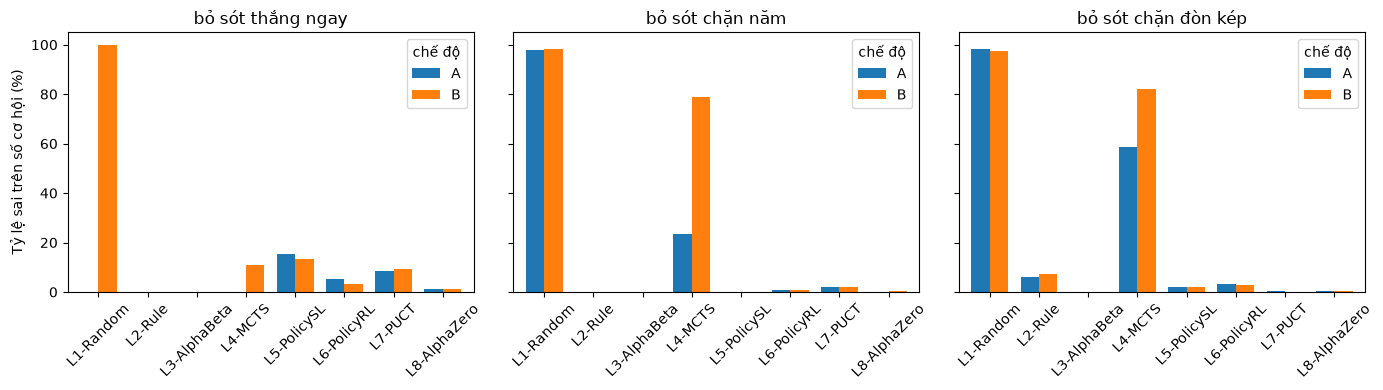

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
rate = table['tỷ lệ sai (%)'].unstack('chế độ')
for ax, category in zip(axes, CATEGORIES, strict=True):
    rate.xs(LABELS[category], level='loại').plot.bar(ax=ax, width=0.75)
    ax.set_title(LABELS[category])
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=45)
axes[0].set_ylabel('Tỷ lệ sai trên số cơ hội (%)')
fig.tight_layout()
fig.savefig(FIGS / 'error_analysis_overview.png', dpi=150)
plt.show()

## Số lỗi theo cấp và loại

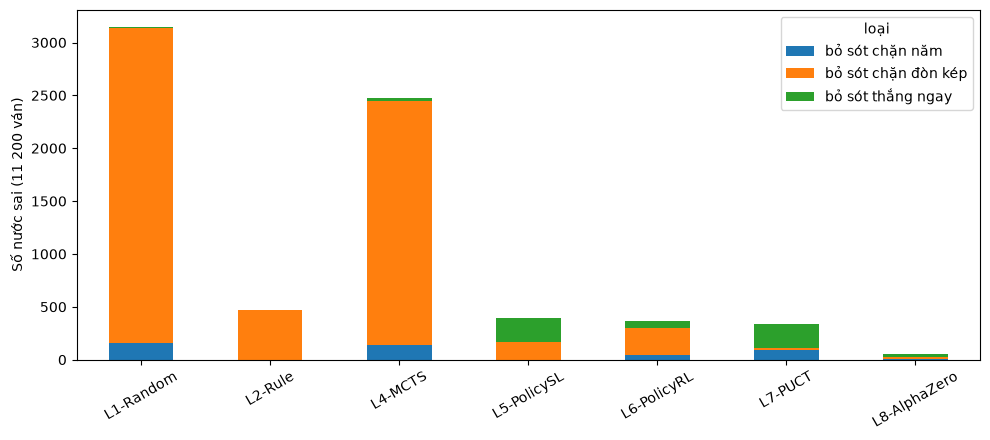

loại,bỏ sót chặn năm,bỏ sót chặn đòn kép,bỏ sót thắng ngay
agent,,,
L1-Random,153,2983,14
L2-Rule,0,466,0
L4-MCTS,136,2314,25
L5-PolicySL,0,168,227
L6-PolicyRL,41,254,70
L7-PUCT,88,18,230
L8-AlphaZero,8,20,28


In [4]:
pivot = errors.assign(loại=errors['category'].map(LABELS)).pivot_table(
    index='agent', columns='loại', values='ply', aggfunc='count', fill_value=0)
ax = pivot.plot.bar(stacked=True, figsize=(10, 4.5))
ax.set_xlabel('')
ax.set_ylabel('Số nước sai (11 200 ván)')
ax.tick_params(axis='x', rotation=30)
ax.figure.tight_layout()
ax.figure.savefig(FIGS / 'error_by_agent_type.png', dpi=150)
plt.show()
pivot

## Ván minh hoạ

Quy tắc chọn định trước: với L7 và L8, lấy ván thua dài nhất có ít nhất một lỗi của chính tác tử đó.

In [5]:
games = {}
for item in summary['runs']:
    for line in (PROJECT_ROOT / item['source'] / 'games.jsonl').open(encoding='utf-8'):
        record = json.loads(line)
        games[item['source'], record['game_id']] = record
errors['số nước'] = [len(games[s, g]['moves']) for s, g in zip(errors['source'], errors['game_id'], strict=True)]
lost = errors[errors['result_for_agent'] == -1]
for agent in ('L7-PUCT', 'L8-AlphaZero'):
    part = lost[lost['agent'] == agent].sort_values(['số nước', 'source', 'game_id', 'ply'],
                                                      ascending=[False, True, True, True])
    first = part.iloc[0]
    same = part[(part['source'] == first['source']) & (part['game_id'] == first['game_id'])]
    print(f"{agent} thua {first['opponent']} | {first['source']} | ván {first['game_id']} | {first['số nước']} nước")
    for _, e in same.iterrows():
        cells = ', '.join(f"{'ABCDEFGHIJK'[m % 11]}{m // 11 + 1}" for m in e['correct'][:8])
        mine = f"{'ABCDEFGHIJK'[e['move'] % 11]}{e['move'] // 11 + 1}"
        print(f"   nước {e['ply'] + 1}: {LABELS[e['category']]}; đi {mine}, nước đúng: {cells}")

L7-PUCT thua L8-AlphaZero | runs/tournament/main_mode_a_l8_additional/20261126-174418 | ván 1225 | 92 nước
   nước 89: bỏ sót chặn đòn kép; đi E1, nước đúng: A11, C11, F11
L8-AlphaZero thua L3-AlphaBeta | runs/tournament/main_mode_b_l8_additional/20261126-221554 | ván 405 | 71 nước
   nước 68: bỏ sót chặn đòn kép; đi I7, nước đúng: D1, G1, I1


## Giới hạn

- Chỉ xét thắng ngay, chặn năm và đe doạ kép trong 4 ply; chuỗi ép dài hơn (VCF, VCT) không được tính.
- Số cơ hội phụ thuộc các thế thực sự xuất hiện, và mỗi tác tử gặp tập thế khác nhau.
- Ở chế độ A, L3, L4, L7, L8 phụ thuộc tốc độ máy; các lượt chạy có tải khác nhau.